# C03a — Audit POS X and retrain without X
Run after C03 in a fresh kernel. This uses the exact C03 input hashes, cached features, human calibration/test sets and base RAID training split. If several completed C03 runs exist, set `RUN_DIR` explicitly below. No texts are edited.

`X` is the Universal POS “other” category, not a synonym for AI language ([definition](https://universaldependencies.org/u/pos/X.html)). Inspect actual spaCy assignments before interpreting their cause. Positive contribution does not establish whether more or fewer X tokens is AI-directed.

The ablation drops all four X coordinates and **retrains** both project-defined POS-extended models. It measures remaining predictive performance, not a causal effect of editing text. Bootstrap intervals condition on fitted models and resample AI and human documents within genre; these are discovery diagnostics.


In [1]:
from pathlib import Path
import json, hashlib, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy, sklearn
from sklearn.base import clone
from sklearn.metrics import roc_curve, roc_auc_score
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'results').exists() else Path.cwd().parent
RUN_DIR=None  # e.g. ROOT/'results/causal/C03_fz186_raid_fixed54/<run hash>'
if RUN_DIR is None:
    runs=sorted(p.parent for p in (ROOT/'results/causal/C03_fz186_raid_fixed54').glob('*/summary.csv'))
    if len(runs)!=1: raise RuntimeError(f'Set RUN_DIR to one completed C03 run: {runs}')
    RUN_DIR=runs[0]
RUN_DIR=Path(RUN_DIR)
contract=json.loads((RUN_DIR/'contract.json').read_text())
manifest=json.loads((RUN_DIR/'feature_manifest.json').read_text())
for rel,expected in contract['inputs'].items():
    assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==expected, f'C03 input changed: {rel}'
assert sklearn.__version__==contract['sklearn'], 'Use the same sklearn environment as C03'
nlp=spacy.load('en_core_web_sm')
assert nlp.meta==manifest['spacy'], 'Use the same spaCy model as C03'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
INPUT=ROOT/'results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv'
data=pd.read_csv(INPUT,keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(data)==54 and data.case_id.is_unique and data.pipeline_status.eq('complete').all()
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
text_map=corpus.set_index('source_id').text.to_dict()
raid=features.loc[features.dataset.eq('raid')].reset_index(drop=True)
normalize=lambda t:str(t).replace('\n',' ').replace('\r',' ')
F186=manifest['feature_names'];POS=[f for f in F186 if f.startswith('pos_') and f.split('_')[-1] in ('share','mean','std','max')]
# Explicit names prevent confusion with inherited POS overlap features.
POS=[f'pos_{tag}_{stat}' for tag in manifest['pos_tags'] for stat in manifest['pos_statistics']]
XCOLS=[f for f in POS if f.startswith('pos_X_')];assert len(XCOLS)==4
inherited=[f for f in F186 if f not in POS]
def cached(t):
    key=hashlib.sha256(normalize(t).encode()).hexdigest()
    return json.loads((RUN_DIR/'pos_cache'/f'{key}.json').read_text())
XR=pd.concat([raid[inherited],pd.DataFrame([cached(text_map[s]) for s in raid.source_id],columns=POS)],axis=1)
XF=pd.read_csv(RUN_DIR/'fixed54_features.csv').set_index('case_id').loc[data.case_id,F186].reset_index(drop=True)
train=raid.split.eq('train').to_numpy()
assert set(data.source_id).isdisjoint(raid.loc[train,'source_id'])
mix=data.domain.value_counts(normalize=True)
cal=(raid.split.eq('validation')&raid.label.eq(0)&raid.domain.isin(mix.index)).to_numpy()
human=(raid.split.eq('test')&raid.label.eq(0)&raid.domain.isin(mix.index)).to_numpy()
def weights(mask):
    g=raid.loc[mask,'domain'];counts=g.value_counts()
    assert set(mix.index)<=set(counts.index)
    return np.array([mix[x]/counts[x] for x in g])
wc,wh=weights(cal),weights(human)
SEED=int(contract['seed']);B=2000
nb=ROOT/'experiments/C03a_POS_X_audit.ipynb'
record={'parent_contract':hashlib.sha256((RUN_DIR/'contract.json').read_bytes()).hexdigest(),
        'code':hashlib.sha256(json.dumps([c['source'] for c in json.loads(nb.read_text())['cells'] if c['cell_type']=='code']).encode()).hexdigest(),
        'removed':XCOLS,'seed':SEED,'bootstraps':B,'python':platform.python_version()}
run=hashlib.sha256(json.dumps(record,sort_keys=True).encode()).hexdigest()[:12]
OUT=ROOT/'results/causal/C03a_POS_X_audit'/run;OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
(OUT/'contract.json').write_text(json.dumps(record,indent=2))
def savefig(fig,stem):
    fig.tight_layout()
    for ext in ('pdf','png'):
        for folder in (OUT,FIG):fig.savefig(folder/f'C03a_{stem}.{ext}',dpi=300,bbox_inches='tight')
    plt.show()
print('Using C03 run:',RUN_DIR)


Using C03 run: ../results/causal/C03_fz186_raid_fixed54/cfa99a0382fb


documents  zero_fraction  mean_X_share  \
group              domain                                              
Fixed AI           abstracts         10       1.000000      0.000000   
                   books              7       0.714286      0.004512   
                   news              12       1.000000      0.000000   
                   recipes            9       0.000000      0.026542   
                   reddit             6       1.000000      0.000000   
                   reviews            1       1.000000      0.000000   
                   wiki               9       1.000000      0.000000   
Human test         abstracts         23       0.652174      0.002381   
                   books             18       0.833333      0.001120   
                   news              25       0.880000      0.000405   
                   recipes           21       0.857143      0.002405   
                   reddit            16       0.875000      0.000793   
                   reviews            6       0.833333      0.000639   
                   wiki              19       0.894737      0.003564   
Original AI source abstracts         10       0.900000      0.000347   
                   books              7       0.714286      0.001224   
                   news              12       0.916667      0.000216   
                   recipes            9       0.000000      0.027250   
                   reddit             6       0.833333      0.001425   
                   reviews            1       1.000000      0.000000   
                   wiki               9       0.888889      0.004193   

                              median_X_share  max_X_share  
group              domain                                  
Fixed AI           abstracts        0.000000     0.000000  
                   books            0.000000     0.028249  
                   news             0.000000     0.000000  
                   recipes          0.026866     0.048193  
                   reddit           0.000000     0.000000  
                   reviews          0.000000     0.000000  
                   wiki             0.000000     0.000000  
Human test         abstracts        0.000000     0.012500  
                   books            0.000000     0.015544  
                   news             0.000000     0.005208  
                   recipes          0.000000     0.045455  
                   reddit           0.000000     0.006944  
                   reviews          0.000000     0.003831  
                   wiki             0.000000     0.064378  
Original AI source abstracts        0.000000     0.003472  
                   books            0.000000     0.005814  
                   news             0.000000     0.002591  
                   recipes          0.027211     0.041096  
                   reddit           0.000000     0.008547  
                   reviews          0.000000     0.000000  
                   wiki             0.000000     0.037736

,group,token,fine_tag,count
41,Original AI source,.,LS,17
0,Fixed AI,.,LS,16
52,Original AI source,>,XX,12
10,Fixed AI,>,XX,12
31,Human test,de,FW,10
43,Original AI source,2,LS,9
39,Human test,rue,FW,8
44,Original AI source,3,LS,8
45,Original AI source,4,LS,8
1,Fixed AI,2,LS,7



gate_0001 [abstracts]: 0/156 X tokens

gate_0003 [news]: 0/414 X tokens

gate_0004 [recipes]: 12/308 X tokens
  '>' (XX) at token 0: > 8-1/2 cups water, divided > 4 small carrots, chopped > 3 stalks celery, diced > 4 cloves garlic, minced > 2 leeks (white part only) cut into pieces > 6 (6 oz.) packages fresh baby spinach leaves > One 4 lb turkey, cooked and diced or shredded > 8 tomatos (or equivalent amount frozen tomatoes) > 2 tsp dried rosemary > 2 bay leaves > Salt & Pepper to taste > Corn meal noodles combine in food processor mix 1 cup cornmeal, 1 teaspoon salt and 4 cups hot tap water; pulse mixture until dough comes together then set aside for 5 minutes.
  '>' (XX) at token 8: > 8-1/2 cups water, divided > 4 small carrots, chopped > 3 stalks celery, diced > 4 cloves garlic, minced > 2 leeks (white part only) cut into pieces > 6 (6 oz.) packages fresh baby spinach leaves > One 4 lb turkey, cooked and diced or shredded > 8 tomatos (or equivalent amount frozen tomatoes) > 2 tsp d

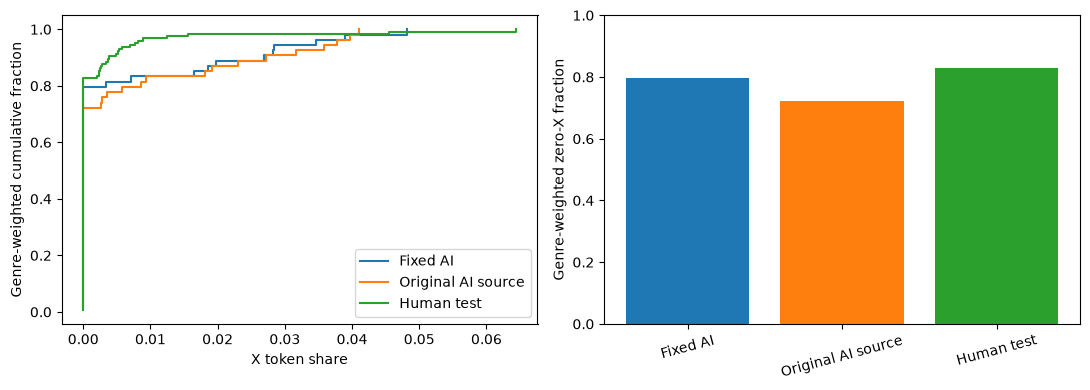

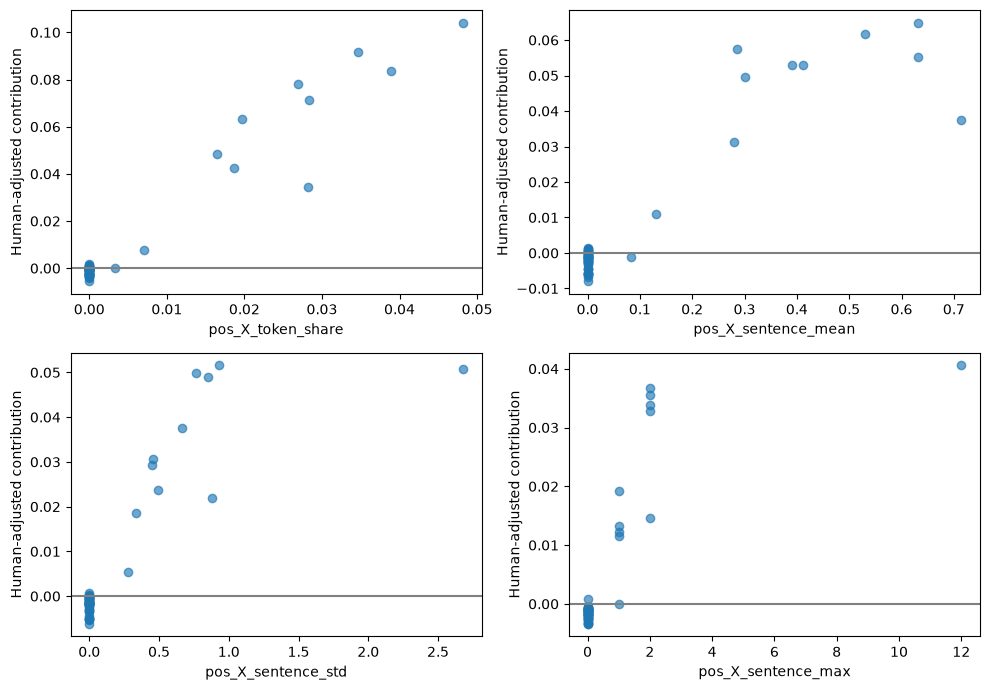

In [2]:
# Inspect fixed AI, original AI sources, and same-genre human test texts.
rows=[];tokens=[]
specs=[('Fixed AI',r.case_id,r.source_id,r.domain,r.text) for r in data.itertuples()]
specs += [('Original AI source',r.case_id,r.source_id,r.domain,text_map[r.source_id]) for r in data.itertuples()]
specs += [('Human test',str(r.source_id),r.source_id,r.domain,text_map[r.source_id]) for r in raid.loc[human].itertuples()]
for spec,doc in zip(specs,nlp.pipe([normalize(s[4]) for s in specs],batch_size=32)):
    group,cid,sid,genre,text=spec
    ts=[t for t in doc if not t.is_space];xs=[t for t in ts if t.pos_=='X']
    counts=np.array([sum(t.pos_=='X' for t in sent if not t.is_space) for sent in doc.sents if any(not t.is_space for t in sent)],float)
    rows.append(dict(group=group,case_id=cid,source_id=sid,domain=genre,n_tokens=len(ts),n_X=len(xs),
        pos_X_token_share=len(xs)/max(1,len(ts)),pos_X_sentence_mean=counts.mean() if len(counts) else 0,
        pos_X_sentence_std=counts.std() if len(counts) else 0,pos_X_sentence_max=counts.max() if len(counts) else 0))
    for t in xs:tokens.append(dict(group=group,case_id=cid,source_id=sid,domain=genre,token=t.text,
        fine_tag=t.tag_,token_index=t.i,character_offset=t.idx,sentence=t.sent.text))
audit=pd.DataFrame(rows)
contexts=pd.DataFrame(tokens,columns=['group','case_id','source_id','domain','token','fine_tag','token_index','character_offset','sentence'])
np.testing.assert_allclose(audit.loc[audit.group.eq('Fixed AI'),XCOLS].to_numpy(),XF[XCOLS].to_numpy(),atol=1e-12)
np.testing.assert_allclose(audit.loc[audit.group.eq('Human test'),XCOLS].to_numpy(),XR.loc[human,XCOLS].to_numpy(),atol=1e-12)
audit.to_csv(OUT/'X_document_audit.csv',index=False);contexts.to_csv(OUT/'X_token_contexts.csv',index=False)
summary=audit.groupby(['group','domain']).agg(documents=('n_X','size'),zero_fraction=('n_X',lambda x:(x==0).mean()),mean_X_share=('pos_X_token_share','mean'),median_X_share=('pos_X_token_share','median'),max_X_share=('pos_X_token_share','max'))
summary.to_csv(OUT/'X_genre_summary.csv');display(summary)
display(contexts.groupby(['group','token','fine_tag']).size().rename('count').reset_index().sort_values('count',ascending=False).head(50))
# Print every fixed-AI X token with context, including identification of zero-X cases.
for r in audit.loc[audit.group.eq('Fixed AI')].itertuples():
    print(f'\n{r.case_id} [{r.domain}]: {r.n_X}/{r.n_tokens} X tokens')
    for t in contexts.loc[contexts.group.eq('Fixed AI')&contexts.case_id.eq(r.case_id)].itertuples():
        print(f'  {t.token!r} ({t.fine_tag}) at token {t.token_index}: {t.sentence}')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for group in audit.group.unique():
    sub=audit.loc[audit.group.eq(group)];g=sub.domain;cnt=g.value_counts();w=np.array([mix[x]/cnt[x] for x in g])
    order=np.argsort(sub.pos_X_token_share.to_numpy());v=sub.pos_X_token_share.to_numpy()[order]
    axs[0].step(v,np.cumsum(w[order]),where='post',label=group)
    axs[1].bar(group,w[sub.n_X.eq(0)].sum())
axs[0].set(xlabel='X token share',ylabel='Genre-weighted cumulative fraction');axs[0].legend()
axs[1].set(ylabel='Genre-weighted zero-X fraction',ylim=(0,1));axs[1].tick_params(axis='x',rotation=15)
savefig(fig,'X_distributions')
# Join raw X values to signed human-adjusted path contributions.
gaps=pd.read_csv(RUN_DIR/'FZ186_case_contribution_gaps.csv').set_index('case_id').loc[data.case_id]
joined=data[['case_id','domain']].copy()
for f in XCOLS:joined[f]=XF[f].to_numpy();joined[f+'_gap']=gaps[f].to_numpy()
joined.to_csv(OUT/'X_values_and_contribution_gaps.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(10,7))
for ax,f in zip(axs.flat,XCOLS):
    ax.scatter(joined[f],joined[f+'_gap'],alpha=.65);ax.axhline(0,color='gray');ax.set(xlabel=f,ylabel='Human-adjusted contribution')
savefig(fig,'X_values_vs_contributions')


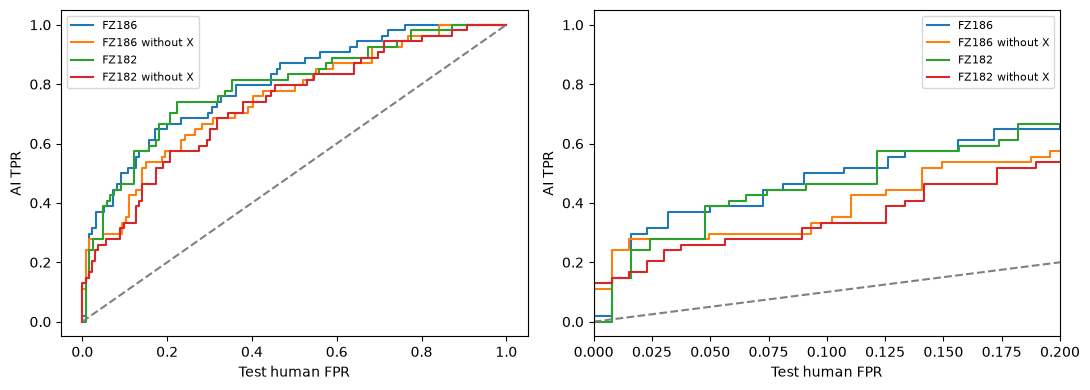

,model,n_features,AUC,mean_AI_score
0,FZ186,186,0.800940,0.540866
1,FZ186 without X,182,0.748183,0.519618
2,FZ182,182,0.790408,0.531238
3,FZ182 without X,178,0.731341,0.507796


,model,requested_FPR,threshold,calibration_FPR,test_FPR,TPR
0,FZ186,0.01,0.653783,0.008418,0.015988,0.222222
1,FZ186,0.05,0.602644,0.049798,0.038906,0.370370
2,FZ186,0.10,0.589020,0.099596,0.050044,0.388889
3,FZ186,0.20,0.520601,0.192703,0.118355,0.518519
4,FZ186,0.30,0.476262,0.294700,0.233352,0.666667
5,FZ186,0.50,0.420166,0.497691,0.405241,0.796296
6,FZ186,1.00,-inf,1.000000,1.000000,1.000000
7,FZ186 without X,0.01,0.636628,0.007407,0.008052,0.240741
8,FZ186 without X,0.05,0.608472,0.041852,0.015253,0.277778
9,FZ186 without X,0.10,0.580779,0.099428,0.049324,0.296296


,comparison,AUC_change,ci_low,ci_high
0,FZ186 without X minus FZ186,-0.052757,-0.088176,-0.018087
1,FZ182 without X minus FZ182,-0.059067,-0.095077,-0.026438


Saved diagnostics: ../results/causal/C03a_POS_X_audit/452eb40b20de ; paper figures: ../figures


In [3]:
# Retrain with X columns removed; keep base training rows and estimator settings.
models={}
for name,filename,cols in [('FZ186','FZ186.pkl',F186),('FZ182','FZ182_matched_exclusions.pkl',[f for f in F186 if f not in manifest['excluded_for_182']])]:
    with (RUN_DIR/filename).open('rb') as f:model=pickle.load(f)
    assert list(model.feature_names_in_)==cols
    models[name]=(model,cols)
    reduced=[f for f in cols if f not in XCOLS]
    ablated=clone(model);ablated.fit(XR.loc[train,reduced],raid.loc[train,'label'].astype(int))
    models[name+' without X']=(ablated,reduced)
    with (OUT/(name+'_without_X.pkl')).open('wb') as f:pickle.dump(ablated,f)
raid.loc[train,['source_id','domain','label','split']].to_csv(OUT/'training_manifest.csv',index=False)
results=[];operating=[];predictions={};scores=data[['case_id','source_id','domain']].copy()
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,(model,cols) in models.items():
    a=model.predict_proba(XF[cols])[:,1];h=model.predict_proba(XR.loc[human,cols])[:,1];c=model.predict_proba(XR.loc[cal,cols])[:,1]
    predictions[name]=(a,h);scores[name]=a
    y=np.r_[np.zeros(len(h)),np.ones(len(a))];w=np.r_[wh,np.ones(len(a))/len(a)]
    fpr,tpr,thresholds=roc_curve(y,np.r_[h,a],sample_weight=w,drop_intermediate=False)
    results.append(dict(model=name,n_features=len(cols),AUC=roc_auc_score(y,np.r_[h,a],sample_weight=w),mean_AI_score=a.mean()))
    for ax in axs:ax.step(fpr,tpr,where='post',label=name)
    cuts=np.r_[np.inf,np.unique(c)[::-1],-np.inf];cf=np.array([wc[c>cut].sum() for cut in cuts])
    for budget in (.01,.05,.1,.2,.3,.5,1.):
        j=np.flatnonzero(cf<=budget+1e-12)[-1];cut=cuts[j]
        operating.append(dict(model=name,requested_FPR=budget,threshold=cut,calibration_FPR=cf[j],test_FPR=wh[h>cut].sum(),TPR=(a>cut).mean()))
for ax in axs:ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Test human FPR',ylabel='AI TPR');ax.legend(fontsize=8)
axs[1].set_xlim(0,.2);savefig(fig,'X_ablation_ROC')
result=pd.DataFrame(results);ops=pd.DataFrame(operating)
result.to_csv(OUT/'ablation_summary.csv',index=False);ops.to_csv(OUT/'ablation_TPR.csv',index=False);scores.to_csv(OUT/'fixed54_scores.csv',index=False)
display(result);display(ops)
# Paired genre-stratified bootstrap: resample the SAME documents for both models.
rng=np.random.default_rng(SEED);boot={name:[] for name in ('FZ186','FZ182')}
ag=data.domain.to_numpy();hg=raid.loc[human,'domain'].to_numpy()
for b in range(B):
    ia=np.concatenate([rng.choice(np.flatnonzero(ag==g),size=sum(ag==g),replace=True) for g in sorted(mix.index)])
    ih=np.concatenate([rng.choice(np.flatnonzero(hg==g),size=sum(hg==g),replace=True) for g in sorted(mix.index)])
    y=np.r_[np.zeros(len(ih)),np.ones(len(ia))];w=np.r_[wh[ih],np.ones(len(ia))/len(ia)]
    for name in boot:
        a,h=predictions[name];aa,hh=predictions[name+' without X']
        boot[name].append(roc_auc_score(y,np.r_[hh[ih],aa[ia]],sample_weight=w)-roc_auc_score(y,np.r_[h[ih],a[ia]],sample_weight=w))
ci=[]
for name,values in boot.items():
    low,high=np.quantile(values,[.025,.975]);s=result.set_index('model').AUC
    ci.append(dict(comparison=name+' without X minus '+name,AUC_change=s[name+' without X']-s[name],ci_low=low,ci_high=high))
ci=pd.DataFrame(ci);ci.to_csv(OUT/'paired_AUC_changes.csv',index=False);display(ci)
print('Saved diagnostics:',OUT,'; paper figures:',FIG)


## Interpretation
Compare ablated performance with the full model at both actual test FPR and AUC. A drop after removing X indicates reliance on that feature group; surviving performance indicates other signals remain. It does not prove the X labels are erroneous or that deleting X tokens would reproduce the ablation. Contexts and genre tables determine whether tagging peculiarities, fragments, formatting, or ordinary lexical material account for the pattern. Zero-X cases remain in all analyses.

PDFs are generated during execution in `reproduction/figures/`: `C03a_X_distributions.pdf`, `C03a_X_values_vs_contributions.pdf`, `C03a_X_ablation_ROC.pdf`. Matching TeX is supplied separately.
